# MedChemExpress Library & SupplementaryTable10 — EDA

Understand the MCE chemical library and the MIC/AP-G data before reproducing Figure 5.

In [1]:
import warnings
warnings.filterwarnings("ignore")
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
import seaborn as sns
from scipy.stats import spearmanr

def find_data_dir():
    here = Path().resolve()
    for c in [here / "data", here.parent / "data"]:
        if (c / "prestwick_library_screened.tsv.gz").exists():
            return c
    raise FileNotFoundError("Cannot find data/")

DATA_DIR = find_data_dir()
MCE_TSV  = DATA_DIR / "mechchem" / "chemical_library_cleaned.tsv"
ST10_XLS = DATA_DIR / "mechchem" / "SupplementaryTable10.xlsx"
print(f"Data dir : {DATA_DIR}")
print(f"MCE file : {MCE_TSV}")
print(f"ST10 file: {ST10_XLS}")

Data dir : D:\Hiwi\GPT+Mole\GPT+Mole\data
MCE file : D:\Hiwi\GPT+Mole\GPT+Mole\data\mechchem\chemical_library_cleaned.tsv
ST10 file: D:\Hiwi\GPT+Mole\GPT+Mole\data\mechchem\SupplementaryTable10.xlsx


## 1. MCE Library Overview

In [2]:
mce = pd.read_csv(MCE_TSV, sep="	")
print(f"Shape: {mce.shape}")
print(f"Columns: {mce.columns.tolist()}")
mce.head(3)

Shape: (3286, 17)
Columns: ['Unnamed: 0', 'Catalog Number', 'Original lib', 'ProductName', 'Synonyms', 'CAS Number', 'Target', 'PathWay', 'Biological Activity', 'Formula', 'URL', 'Research Area', 'atc_code', 'rdkit_no_salt', 'pchem_isomeric_smile', 'final_abx', 'atc_description']


,Unnamed: 0,Catalog Number,Original lib,ProductName,Synonyms,CAS Number,Target,PathWay,Biological Activity,Formula,URL,Research Area,atc_code,rdkit_no_salt,pchem_isomeric_smile,final_abx,atc_description
0,0,HY-B1898,1-FDAapproved 2- 3-,Metadoxine,0,74536-44-0,PKA,Protein Tyrosine Kinase/RTK; Stem Cell/Wnt,Metadoxine blocks adipocyte differentiation in...,C13H18N2O6,https://www.medchemexpress.com/Metadoxine.html,Metabolic Disease,A05BA09,Cc1ncc(CO)c(CO)c1O.O=C1CCC(C(=O)O)N1,CC1=NC=C(C(=C1O)CO)CO.C1CC(=O)N[C@@H]1C(=O)O,not_abx,ALIMENTARY TRACT AND METABOLISM - BILE AND LIV...
1,1,HY-B0983,1-FDAapproved 2- 3-,Hydrocortisone 17-butyrate,Cortisol 17-butyrate; Hydrocortisone butyrate,13609-67-1,Adrenergic Receptor,GPCR/G Protein; Neuronal Signaling,Hydrocortisone 17-butyrate is an adrenocortico...,C25H36O6,https://www.medchemexpress.com/Hydrocortisone-...,Inflammation/Immunology; Endocrinology,A01AC03:A07EA02:C05AA01:D07AA02:D07XA01:H02AB0...,CCCC(=O)OC1(C(=O)CO)CCC2C3CCC4=CC(=O)CCC4(C)C3...,CCCC(=O)O[C@@]1(CC[C@@H]2[C@@]1(C[C@@H]([C@H]3...,not_abx,NaN
2,2,HY-B1892,1-FDAapproved 2- 3-,Cefazolin,0,25953-19-9,Antibiotic; Bacterial,Anti-infection,Cefazolin is an antibiotic used for the resear...,C14H14N8O4S3,https://www.medchemexpress.com/cefazolin.html,Infection; Inflammation/Immunology; Neurologic...,J01DB04,Cc1nnc(SCC2=C(C(=O)O)N3C(=O)C(NC(=O)Cn4cnnn4)C...,CC1=NN=C(S1)SCC2=C(N3[C@@H]([C@@H](C3=O)NC(=O)...,abx,NaN


In [5]:
# final_abx distribution
print("final_abx counts:")
print(mce["final_abx"].value_counts(dropna=False))
print(f"Valid rdkit_no_salt SMILES: {mce['rdkit_no_salt'].notna().sum()} / {len(mce)}")

final_abx counts:
final_abx
not_abx    3055
abx         231
Name: count, dtype: int64
Valid rdkit_no_salt SMILES: 3286 / 3286


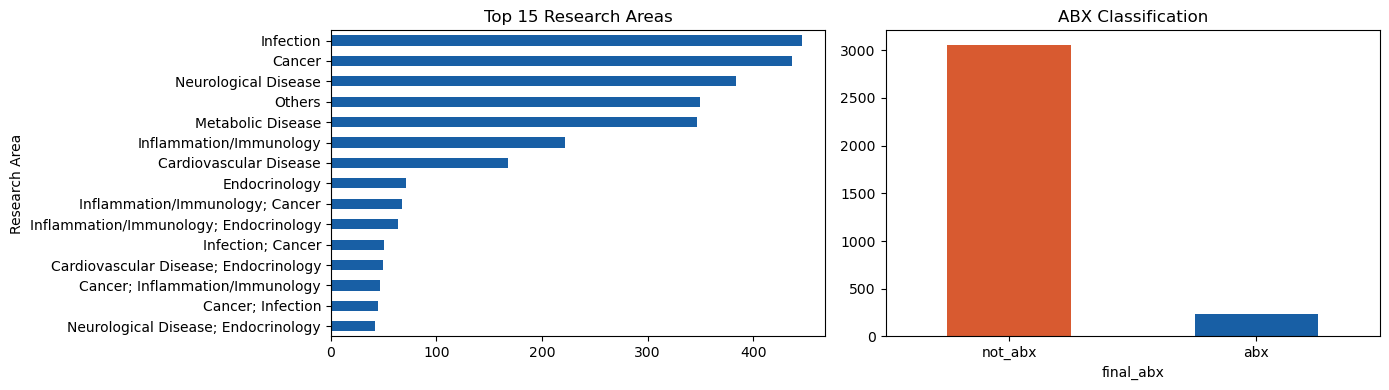

In [6]:
# Top research areas
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
mce["Research Area"].value_counts().head(15).plot.barh(ax=axes[0], color="#185FA5")
axes[0].set_title("Top 15 Research Areas"); axes[0].invert_yaxis()

mce["final_abx"].value_counts().plot.bar(ax=axes[1], color=["#D85A30", "#185FA5"])
axes[1].set_title("ABX Classification"); axes[1].set_xticklabels(axes[1].get_xticklabels(), rotation=0)
plt.tight_layout()
plt.show()

## 2. SupplementaryTable10 Overview

In [7]:
# header is at row index 6 (skip 6 rows of description)
st10 = pd.read_excel(ST10_XLS, sheet_name="ST 10", header=6)
print(f"Shape: {st10.shape}")
print(f"Columns: {st10.columns.tolist()}")
st10.head(5)

Shape: (44, 14)
Columns: ['Catalog Number', 'ProductName', 'Predicted by', 'MIC_gpositive', 'MIC_gnegative', 'Target_bacteria', 'Notes', 'Reference', 'apscore_total.MolE', 'apscore_gnegative.MolE', 'apscore_gpositive.MolE', 'apscore_total.ECFP4', 'apscore_gnegative.ECFP4', 'apscore_gpositive.ECFP4']


,Catalog Number,ProductName,Predicted by,MIC_gpositive,MIC_gnegative,Target_bacteria,Notes,Reference,apscore_total.MolE,apscore_gnegative.MolE,apscore_gpositive.MolE,apscore_total.ECFP4,apscore_gnegative.ECFP4,apscore_gpositive.ECFP4
0,HY-B1400,Diiodohydroxyquinoline,MolE / ECFP4,0.125,NaN,Clostridium difficile,NaN,PMID: 32253206,-1.715090,-1.781474,-1.660777,-3.067798,-3.367379,-2.822687
1,HY-B1212,Broxyquinoline,MolE,0.250,NaN,Clostridium difficile,NaN,PMID: 38940508,-1.035615,-0.998377,-1.066083,NaN,NaN,NaN
2,HY-B1360,Chlorquinaldol,MolE / ECFP4,0.250,NaN,Staphylococcus aureus,NaN,PMID: 31410037,-4.132725,-4.420965,-3.896893,-1.341939,-1.657102,-1.084078
3,HY-17592,Bithionol,MolE / ECFP4,0.890,NaN,Mycobacterium abscessus,NaN,PMID: 38927195,-0.459424,-0.523412,-0.407069,-2.834938,-3.353294,-2.410828
4,HY-10446,Pralatrexate,MolE,0.950,NaN,Streptococcus suis,NaN,PMID: 34800069,-4.566516,-5.559006,-3.754478,NaN,NaN,NaN


In [8]:
print("Predicted by value counts:")
print(st10["Predicted by"].value_counts(dropna=False))

ap_cols = [c for c in st10.columns if "apscore" in c.lower()]
print(f"AP-score columns: {ap_cols}")
print(st10[ap_cols].describe().round(3))

Predicted by value counts:
Predicted by
MolE            24
MolE / ECFP4    12
ECFP4            8
Name: count, dtype: int64
AP-score columns: ['apscore_total.MolE', 'apscore_gnegative.MolE', 'apscore_gpositive.MolE', 'apscore_total.ECFP4', 'apscore_gnegative.ECFP4', 'apscore_gpositive.ECFP4']
       apscore_total.MolE  apscore_gnegative.MolE  apscore_gpositive.MolE  \
count              36.000                  36.000                  36.000   
mean               -4.435                  -5.289                  -3.736   
std                 1.844                   2.254                   1.766   
min                -7.838                  -9.456                  -8.083   
25%                -5.502                  -6.857                  -4.646   
50%                -4.745                  -5.876                  -3.922   
75%                -3.199                  -4.285                  -2.613   
max                -0.459                  -0.523                  -0.350   

       apscor

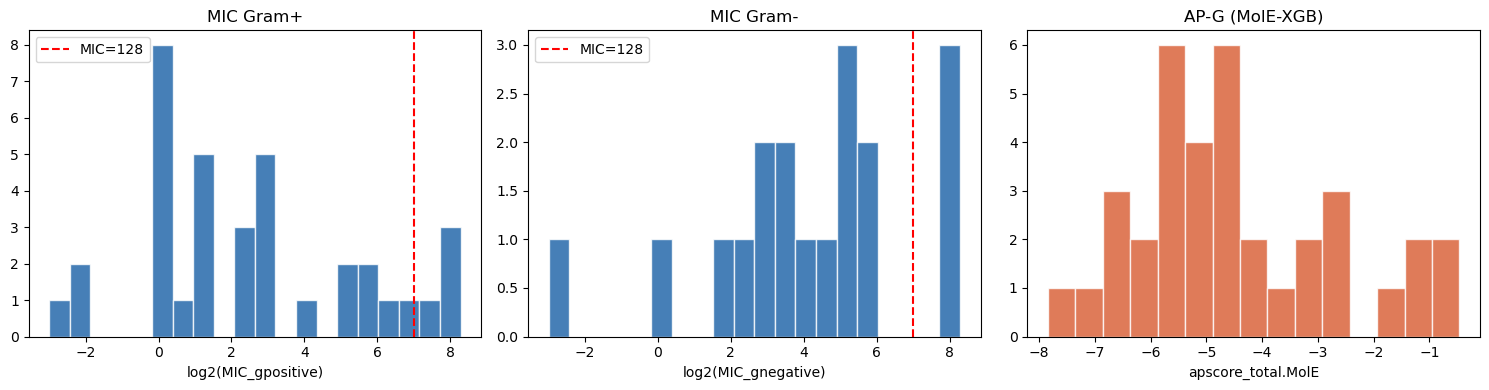

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

# MIC distributions
for col, ax, label in [("MIC_gpositive", axes[0], "MIC Gram+"),
                        ("MIC_gnegative", axes[1], "MIC Gram-")]:
    vals = st10[col].dropna()
    ax.hist(np.log2(vals.clip(lower=1e-3)), bins=20, color="#185FA5", alpha=0.8, edgecolor="white")
    ax.set_xlabel(f"log2({col})"); ax.set_title(label)
    ax.axvline(np.log2(128), color="red", linestyle="--", label="MIC=128")
    ax.legend()

# AP-G distribution (MolE)
mole_ap = st10["apscore_total.MolE"].dropna()
axes[2].hist(mole_ap, bins=15, color="#D85A30", alpha=0.8, edgecolor="white")
axes[2].set_xlabel("apscore_total.MolE"); axes[2].set_title("AP-G (MolE-XGB)")

plt.tight_layout()
plt.show()

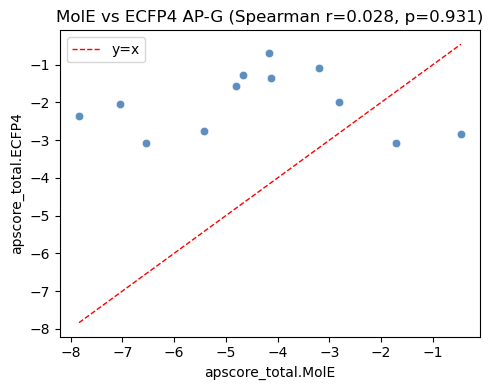

In [10]:
# AP-G: MolE vs ECFP4 agreement
both = st10[["apscore_total.MolE", "apscore_total.ECFP4"]].dropna()
r, p = spearmanr(both["apscore_total.MolE"], both["apscore_total.ECFP4"])
fig, ax = plt.subplots(figsize=(5, 4))
ax.scatter(both["apscore_total.MolE"], both["apscore_total.ECFP4"],
           alpha=0.7, color="#185FA5", edgecolors="white", linewidth=0.5)
ax.set_xlabel("apscore_total.MolE"); ax.set_ylabel("apscore_total.ECFP4")
ax.set_title(f"MolE vs ECFP4 AP-G (Spearman r={r:.3f}, p={p:.3f})")
mn, mx = min(both.min()), max(both.max())
ax.plot([mn, mx], [mn, mx], "r--", lw=1, label="y=x"); ax.legend()
plt.tight_layout(); plt.show()

## 3. Overlap: ST10 ↔ MCE Library

In [11]:
merged = st10.merge(mce[["ProductName", "rdkit_no_salt", "final_abx"]],
                    on="ProductName", how="left")
n_matched = merged["rdkit_no_salt"].notna().sum()
print(f"ST10 rows: {len(st10)}")
print(f"Matched in MCE library: {n_matched} / {len(st10)}")
print(f"Missing SMILES: {merged[merged['rdkit_no_salt'].isna()]['ProductName'].tolist()}")
merged[["ProductName", "Predicted by", "MIC_gpositive", "MIC_gnegative",
        "apscore_total.MolE", "rdkit_no_salt"]].head(8)

ST10 rows: 44
Matched in MCE library: 37 / 44
Missing SMILES: ['Avatrombopag', 'Emamectin', 'Glutathione', 'alpha-Tocopherol', 'Benzalkonium', 'Domiphen', 'Octenidine']


,ProductName,Predicted by,MIC_gpositive,MIC_gnegative,apscore_total.MolE,rdkit_no_salt
0,Diiodohydroxyquinoline,MolE / ECFP4,0.125,NaN,-1.715090,Oc1c(I)cc(I)c2cccnc12
1,Broxyquinoline,MolE,0.250,NaN,-1.035615,Oc1c(Br)cc(Br)c2cccnc12
2,Chlorquinaldol,MolE / ECFP4,0.250,NaN,-4.132725,Cc1ccc2c(Cl)cc(Cl)c(O)c2n1
3,Bithionol,MolE / ECFP4,0.890,NaN,-0.459424,Oc1c(Cl)cc(Cl)cc1Sc1cc(Cl)cc(Cl)c1O
4,Pralatrexate,MolE,0.950,NaN,-4.566516,C#CCC(Cc1cnc2nc(N)nc(N)c2n1)c1ccc(C(=O)NC(CCC(...
5,Fenticonazole (Nitrate),MolE / ECFP4,1.000,0.125,-4.166968,Clc1ccc(C(Cn2ccnc2)OCc2ccc(Sc3ccccc3)cc2)c(Cl)c1
6,(20S)-Protopanaxadiol,MolE,1.000,50.000,-5.603265,CC(C)=CCCC(C)(O)C1CCC2(C)C1C(O)CC1C3(C)CCC(O)C...
7,(20S)-Protopanaxatriol,MolE,1.000,NaN,-6.000750,CC(C)=CCCC(C)(O)C1CCC2(C)C1C(O)CC1C3(C)CCC(O)C...


## 4. The ~39 Figure 5 Compounds

In [12]:
# Filter: MolE-predicted compounds with at least one MIC <= 128
fig5_df = st10[st10["Predicted by"].str.contains("MolE", na=False)].copy()
has_mic = (
    (fig5_df["MIC_gpositive"].notna() & (fig5_df["MIC_gpositive"] <= 128)) |
    (fig5_df["MIC_gnegative"].notna() & (fig5_df["MIC_gnegative"] <= 128))
)
fig5_df = fig5_df[has_mic].reset_index(drop=True)
print(f"Figure 5 compounds (MolE + MIC<=128): {len(fig5_df)}")
fig5_df[["ProductName", "MIC_gpositive", "MIC_gnegative",
          "Target_bacteria", "apscore_total.MolE"]]

Figure 5 compounds (MolE + MIC<=128): 32


,ProductName,MIC_gpositive,MIC_gnegative,Target_bacteria,apscore_total.MolE
0,Diiodohydroxyquinoline,0.125,NaN,Clostridium difficile,-1.715090
1,Broxyquinoline,0.250,NaN,Clostridium difficile,-1.035615
2,Chlorquinaldol,0.250,NaN,Staphylococcus aureus,-4.132725
3,Bithionol,0.890,NaN,Mycobacterium abscessus,-0.459424
4,Pralatrexate,0.950,NaN,Streptococcus suis,-4.566516
5,Fenticonazole (Nitrate),1.000,0.125,"Staphylococcus aureus, Escherichia coli",-4.166968
6,(20S)-Protopanaxadiol,1.000,50.000,"Staphylococcus capitis, Helicobacter pylori",-5.603265
7,(20S)-Protopanaxatriol,1.000,NaN,Staphylococcus capitis,-6.000750
8,Doxifluridine,1.000,NaN,Enterococcus faecium,-3.200107
9,Everolimus,1.000,NaN,Mycobacterium tuberculosis,-2.607874


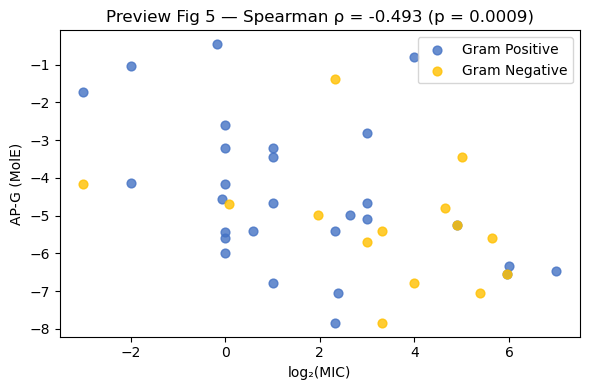

n=42 compound-species combinations


In [13]:
# Preview scatter: log2(MIC) vs AP-G
gpos = fig5_df[fig5_df["MIC_gpositive"].notna()].copy()
gpos["log2_MIC"] = np.log2(gpos["MIC_gpositive"])
gneg = fig5_df[fig5_df["MIC_gnegative"].notna()].copy()
gneg["log2_MIC"] = np.log2(gneg["MIC_gnegative"])
preview = pd.concat([
    gpos.assign(gram="Positive"),
    gneg.assign(gram="Negative")
])

r, p = spearmanr(preview["log2_MIC"], preview["apscore_total.MolE"])
fig, ax = plt.subplots(figsize=(6, 4))
for gram, color in [("Positive", "#4472C4"), ("Negative", "#FFC000")]:
    sub = preview[preview["gram"] == gram]
    ax.scatter(sub["log2_MIC"], sub["apscore_total.MolE"],
               color=color, label=f"Gram {gram}", alpha=0.8, s=40)
ax.set_xlabel("log₂(MIC)"); ax.set_ylabel("AP-G (MolE)")
ax.set_title(f"Preview Fig 5 — Spearman ρ = {r:.3f} (p = {p:.4f})")
ax.legend(); plt.tight_layout(); plt.show()
print(f"n={len(preview)} compound-species combinations")